In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

SCALING_WEIGHTS = [100/15, 100/8, 100/100]

In [2]:
data = pd.read_pickle("ml_data_onsite_start.pickle")
for key in data.keys():
    print(key)

X
y


In [3]:
for key in data["X"].keys():
    print(key)

train
val
live_test


In [4]:
for key in data["y"].keys():
    print(key)

train
val


In [5]:
X_train = data["X"]["train"]
y_train = data["y"]["train"]

X_val = data["X"]["val"]
y_val = data["y"]["val"]

X_test = data["X"]["live_test"]

In [6]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape

((2024, 5, 5, 5, 6), (2024, 3), (376, 5, 5, 5, 6), (376, 3), (200, 5, 5, 5, 6))

In [7]:
def vis(arr):
    plt.figure(figsize=(8, 8))

    cnt = 1
    for z in range(5):
        for q in range(6):
            plt.subplot(5, 6, cnt)
            plt.imshow(arr[:, :, z, q], vmin=-40, vmax=40, cmap='hsv')
            plt.grid()
            plt.axis('off')
            cnt += 1

    plt.tight_layout()

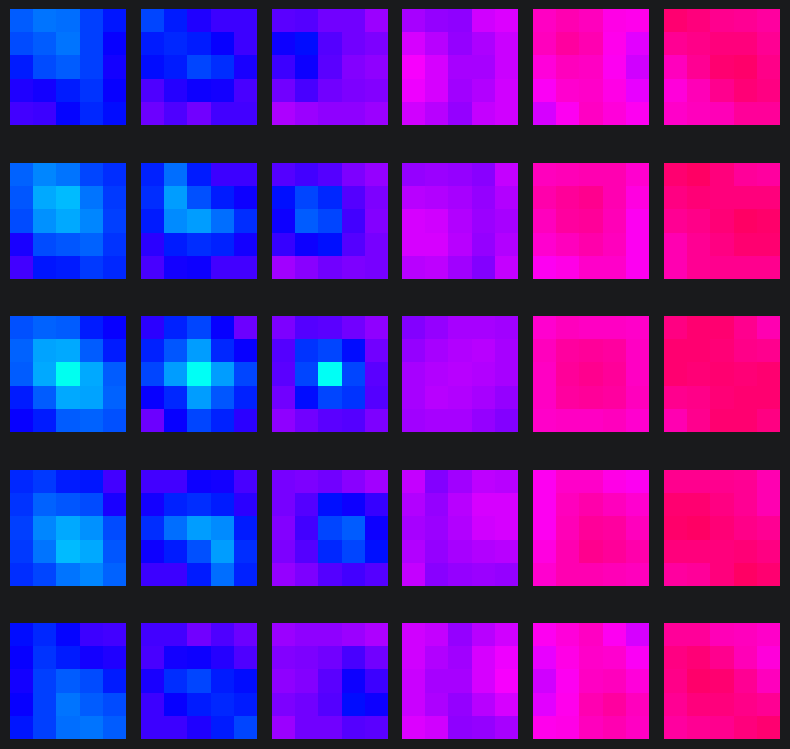

In [8]:
vis(X_train[0])

In [27]:
def test_solution(X_train, y_train, X_val, y_val, feature_num=0):
    assert X_train.shape[-1] <= 300, "Too many features! Should be less than 300"
    assert X_val.shape[-1] <= 300, "Too many features! Should be less than 300"

    model =  LinearRegression().fit(
        X_train,
        y_train[:, feature_num]
    )
    predictions = model.predict(X_val)
    rmse = mean_squared_error(
        predictions,
        y_val[:, feature_num]
    )**.5
    normalized_rmse = rmse * SCALING_WEIGHTS[feature_num]
    print(f"Property #{feature_num}:    raw RMSE={rmse:.6f}")
    print(f"Property #{feature_num}: scaled RMSE={normalized_rmse:.6f}")
    return round(normalized_rmse, 6)

In [16]:
# data augmentation
from itertools import permutations

def data_augmentation(X_tr, y_tr):
    perm = list(permutations((1, 2, 3)))

    X_aug = np.concatenate([
        X_tr.transpose(0, *p, 4)
        for p in perm
    ], axis=0)

    y_aug = np.tile(y_tr, (6, 1))

    return X_aug, y_aug

In [17]:
# hyper to vector before PCA

def hyper_to_vector(X):
    return X.reshape(X.shape[0], -1)

In [19]:
# only one good data

def make_features(X):
    bgs = []

    for _x in X:
        bg = _x[:, :, :, 3].ravel().min() - _x[:, :, :, 2].ravel().max()
        bgs.append(bg)

    bgs = np.array(bgs)
    return bgs[:, None]

In [20]:
X_train_symm, y_train_symm = data_augmentation(X_train, y_train)

In [21]:
X_train_bg = make_features(X_train_symm)
X_val_bg = make_features(X_val)

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=299)
X_train_pca = pca.fit_transform(hyper_to_vector(X_train_symm))
X_val_pca = pca.transform(hyper_to_vector(X_val))

In [25]:
%%time
total_score = 0
for feature_number in range(3):
  total_score += test_solution(
      X_train_pca,
      y_train_symm,
      X_val_pca,
      y_val,
      feature_num=feature_number
  )
  print()
total_score /= 3
print('='*16)
print(f"Total score = {total_score:.6f}")

Property #0:    raw RMSE=0.305542
Property #0: scaled RMSE=2.036950

Property #1:    raw RMSE=0.596131
Property #1: scaled RMSE=7.451637

Property #2:    raw RMSE=1.631475
Property #2: scaled RMSE=1.631475

Total score = 3.706687
CPU times: user 4.82 s, sys: 53.2 ms, total: 4.88 s
Wall time: 504 ms


In [26]:
%%time
total_score = 0
# something close to the best possible solution
for feature_number in range(3):
  total_score += test_solution(
      np.concatenate([X_train_pca, X_train_bg], axis=-1),
      y_train_symm,
      np.concatenate([X_val_pca, X_val_bg], axis=-1),
      y_val,
      feature_num=feature_number
  )
  print()
total_score /= 3
print('='*16)
print(f"Total score = {total_score:.6f}")

Property #0:    raw RMSE=0.306166
Property #0: scaled RMSE=2.041108

Property #1:    raw RMSE=0.102724
Property #1: scaled RMSE=1.284045

Property #2:    raw RMSE=1.628523
Property #2: scaled RMSE=1.628523

Total score = 1.651225
CPU times: user 5.13 s, sys: 37.5 ms, total: 5.17 s
Wall time: 531 ms


In [10]:
def dummy_feature_extractor(X):
    X_new = X.reshape((X.shape[0], -1)) # ravel
    X_new = X_new[:, :300] # pick first 300 features
    return X_new

In [11]:
dummy_feature_extractor(X_train).shape

(2024, 300)

In [12]:
%%time
total_score = 0
for feature_number in range(3):
  total_score += test_solution(
      dummy_feature_extractor(X_train),
      y_train,
      dummy_feature_extractor(X_val),
      y_val,
      feature_num=feature_number
  )
  print()
total_score /= 3
print('='*16)
print(f"Total score = {total_score:.6f}")

Property #0:    raw RMSE=0.464549
Property #0: scaled RMSE=3.096994

Property #1:    raw RMSE=1.170135
Property #1: scaled RMSE=14.626686

Property #2:    raw RMSE=2.729781
Property #2: scaled RMSE=2.729781

Total score = 6.817820
CPU times: user 1.74 s, sys: 8.78 ms, total: 1.75 s
Wall time: 177 ms


In [14]:
def generate_predictions(X_train, y_train, X_test, feature_num=0):
    assert X_train.shape[-1] <= 300
    assert X_test.shape[-1] <= 300

    model =  LinearRegression().fit(
        X_train,
        y_train[:, feature_num]
    )
    predictions = model.predict(X_test)
    return predictions


## Generate solutions and write to the file
combined = {'ID': np.arange(X_test.shape[0])}

for feature_number in range(3):
    predictions = generate_predictions(
        dummy_feature_extractor(X_train),
        y_train,
        dummy_feature_extractor(X_test),
        feature_num=feature_number
    )

    combined[f'y{feature_number+1}'] = predictions

pd.DataFrame(combined).to_csv('predictions.csv', index=False)

In [15]:
# load the test dataset
loaded = pd.read_pickle("Solution/test_set/ml_data_onsite_final_test.pickle")
X_test_final = loaded['X']['final_test']


# make final predictions
combined = {'ID': np.arange(X_test_final.shape[0])}

for feature_number in range(3):
    predictions = generate_predictions(
        dummy_feature_extractor(X_train),
        y_train,
        dummy_feature_extractor(X_test_final),
        feature_num=feature_number
    )

    combined[f'y{feature_number+1}'] = predictions

pd.DataFrame(combined).to_csv('final_predictions.csv', index=False)